# Hospital-restricted k-NN Grid Search for the Attention-Fusion GCN

This notebook searches for a useful `k` for the hospital-restricted cosine k-NN graph used by the attention-fusion GCN. It uses the existing embedding NPZ train/validation partitions and the globally mapped hospital ID for each patient.

- Candidate `k` values are compared using **validation AUPRC only**.
- The GCN architecture and optimizer settings are held fixed to the selected configuration from the previous GCN search.
- The test embedding file is not loaded or evaluated in this notebook.
- Patient IDs are mapped across all `hospital_*/tabular/tabular_features.parquet` files using `patientunitstayid`.
- Edges are restricted to patients from the same hospital within each embedding split.

**Evaluation scope:** the current embeddings are partitioned by patient, not by hospital. This is appropriate for patient-level evaluation. The final full working pipeline uses a strict hospital-wise partition.

## 1. Imports, paths, and search settings

In [7]:
import sys
from pathlib import Path
import gc
import json
import random
import warnings

import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import average_precision_score
from sklearn.neighbors import NearestNeighbors

# Filter harmless PyTorch sparse invariant warnings on MPS
warnings.filterwarnings("ignore", message=".*Sparse invariant checks.*")

_start = Path.cwd().resolve()
_candidates = [_start, *_start.parents]
PROJECT_ROOT = next(
    (
        p for p in _candidates
        if (p / "checkpoints").is_dir() and (p / "processed").is_dir()
    ),
    _start,
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

EMBEDDING_DIR = PROJECT_ROOT / "checkpoints" / "fusion" / "attention_embeddings"
GRAPH_DIR = PROJECT_ROOT / "checkpoints" / "fusion" / "patient_graphs_knn"
SPLIT_PATH = PROJECT_ROOT / "processed" / "hospital_split.json"
HOSPITALS_DIR = PROJECT_ROOT / "processed" / "hospitals"
OUTPUT_DIR = PROJECT_ROOT / "checkpoints" / "fusion" / "gnn_attention"
FIGURES_DIR = PROJECT_ROOT / "figures"

EMBEDDING_DIR.mkdir(parents=True, exist_ok=True)
GRAPH_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Self-healing: auto-extract attention embeddings if missing
for split in ("train", "val"):
    split_file = EMBEDDING_DIR / f"attention_embeddings_{split}.npz"
    if not split_file.is_file():
        print(f"Extracting missing {split_file.name} from attention baseline...")
        from torch.utils.data import DataLoader, TensorDataset
        
        class AttentionFusionClassifier(nn.Module):
            def __init__(self, embedding_dim=64, num_heads=4, dropout=0.25):
                super().__init__()
                self.attention = nn.MultiheadAttention(embedding_dim, num_heads, dropout=dropout, batch_first=True)
                self.norm1 = nn.LayerNorm(embedding_dim)
                self.ffn = nn.Sequential(
                    nn.Linear(embedding_dim, embedding_dim * 2),
                    nn.ReLU(),
                    nn.Dropout(dropout),
                    nn.Linear(embedding_dim * 2, embedding_dim)
                )
                self.norm2 = nn.LayerNorm(embedding_dim)
                self.classifier = nn.Sequential(
                    nn.Linear(embedding_dim, 64),
                    nn.ReLU(),
                    nn.Dropout(dropout),
                    nn.Linear(64, 1)
                )

            def encode(self, temporal, tabular):
                modalities = torch.stack([temporal, tabular], dim=1)
                attended, _ = self.attention(modalities, modalities, modalities, need_weights=False)
                x = self.norm1(modalities + attended)
                x = self.norm2(x + self.ffn(x))
                return x.mean(dim=1)

        dev = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
        m = AttentionFusionClassifier().to(dev)
        st = torch.load(PROJECT_ROOT / "checkpoints" / "fusion" / "attention_baseline" / "attention_classifier.pt", map_location=dev, weights_only=True)
        m.load_state_dict(st)
        m.eval()

        sc = np.load(PROJECT_ROOT / "checkpoints" / "fusion" / "attention_baseline" / "input_scaler.npz")
        t_arr = np.load(PROJECT_ROOT / "checkpoints" / f"temporal_embeddings_{split}.npy")
        pids_arr = np.load(PROJECT_ROOT / "checkpoints" / f"temporal_patient_ids_{split}.npy").reshape(-1)
        labels_arr = np.load(PROJECT_ROOT / "checkpoints" / f"temporal_labels_{split}.npy").reshape(-1)
        tab_arr = np.load(PROJECT_ROOT / "checkpoints" / f"tabular_embeddings_{split}.npz")["embeddings"]

        t_norm = ((t_arr - sc["temporal_mean"]) / sc["temporal_std"]).astype(np.float32)
        tab_norm = ((tab_arr - sc["tabular_mean"]) / sc["tabular_std"]).astype(np.float32)

        ldr = DataLoader(TensorDataset(torch.from_numpy(t_norm), torch.from_numpy(tab_norm)), batch_size=4096, shuffle=False)
        batches = []
        with torch.inference_mode():
            for tb, sb in ldr:
                batches.append(m.encode(tb.to(dev), sb.to(dev)).cpu().numpy())
        emb_arr = np.concatenate(batches, axis=0)
        np.savez_compressed(split_file, embeddings=emb_arr, patient_ids=pids_arr, labels=labels_arr)
        print(f"  -> Generated {split_file.name}: shape={emb_arr.shape}")

# Candidate graph neighborhood sizes.
K_GRID = [5, 10, 15, 20, 30]
K_MAX = max(K_GRID)

# Hold the best GCN hyperparameters from your previous model search fixed.
SEED = 42
HIDDEN_DIM = 256
DROPOUT = 0.35
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
MAX_EPOCHS = 80
PATIENCE = 10

print("Project root:", PROJECT_ROOT)
print("Embedding directory:", EMBEDDING_DIR)
print("Graph directory:", GRAPH_DIR)
print("Hospital metadata (diagnostic only):", SPLIT_PATH)
print("Candidate k values:", K_GRID)
print("Fixed GCN config:", {
    "hidden_dim": HIDDEN_DIM,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
})


Project root: /Users/aryandwivedi/Desktop/Project Hail Minor
Embedding directory: /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/fusion/attention_embeddings
Graph directory: /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/fusion/patient_graphs_knn
Hospital metadata (diagnostic only): /Users/aryandwivedi/Desktop/Project Hail Minor/processed/hospital_split.json
Candidate k values: [5, 10, 15, 20, 30]
Fixed GCN config: {'hidden_dim': 256, 'dropout': 0.35, 'learning_rate': 0.001, 'weight_decay': 1e-05}


## 2. Helper functions: load embeddings and identify each patient's hospital

In [8]:
def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if torch.backends.mps.is_available():
        try:
            torch.mps.manual_seed(seed)
        except Exception:
            pass


def first_key(npz_file, candidates):
    for key in candidates:
        if key in npz_file.files:
            return npz_file[key]
    raise KeyError(f"Expected one of {candidates}; available keys: {npz_file.files}")


def normalize_patient_id(value) -> str:
    """Normalize integer IDs whether loaded as int, float, bytes, or string."""
    if isinstance(value, bytes):
        value = value.decode("utf-8")
    text = str(value).strip()
    try:
        number = float(text)
        if np.isfinite(number) and number.is_integer():
            return str(int(number))
    except (TypeError, ValueError):
        pass
    return text


def load_embeddings(split: str):
    """Load raw attention-fused embeddings, patient IDs, and binary labels."""
    path = EMBEDDING_DIR / f"attention_embeddings_{split}.npz"
    if not path.is_file():
        raise FileNotFoundError(f"Embedding file not found: {path}")

    with np.load(path, allow_pickle=True) as z:
        x = first_key(z, ("embeddings", "fused_embeddings", "features", "X"))
        ids = first_key(z, ("patient_ids", "ids", "pids"))
        y = first_key(z, ("labels", "y", "target"))

    x = np.asarray(x, dtype=np.float32)
    ids = np.asarray(ids).reshape(-1)
    y = np.asarray(y).reshape(-1).astype(np.int64)

    if x.ndim != 2 or len(x) != len(ids) or len(y) != len(ids):
        raise ValueError(f"Shape mismatch in {path}: X={x.shape}, IDs={ids.shape}, y={y.shape}")
    if not np.isfinite(x).all():
        raise ValueError(f"Non-finite embedding values found in {path}")
    if not set(np.unique(y).tolist()).issubset({0, 1}):
        raise ValueError(f"Expected binary labels 0/1 in {path}")
    ids_norm = [normalize_patient_id(pid) for pid in ids]
    if len(set(ids_norm)) != len(ids_norm):
        raise ValueError(f"Duplicate patient IDs found in {path}")
    return x, ids, y


_GLOBAL_PATIENT_TO_HOSPITAL = None


def build_global_patient_to_hospital():
    """Fast-load patient-to-hospital mapping from mapping CSV, with fallback to Parquet scan."""
    global _GLOBAL_PATIENT_TO_HOSPITAL
    if _GLOBAL_PATIENT_TO_HOSPITAL is not None:
        return _GLOBAL_PATIENT_TO_HOSPITAL

    mapping_csv = PROJECT_ROOT / "processed" / "mapping" / "patient_to_hospital.csv"
    if mapping_csv.is_file():
        df_map = pd.read_csv(mapping_csv, dtype={"patientunitstayid": str, "hospitalid": str})
        patient_to_hospital = {
            normalize_patient_id(pid): f"hospital_{hid}"
            for pid, hid in zip(df_map["patientunitstayid"], df_map["hospitalid"])
        }
        _GLOBAL_PATIENT_TO_HOSPITAL = patient_to_hospital
        print(f"Fast-loaded hospital mappings for {len(patient_to_hospital):,} patients from mapping CSV.")
        return _GLOBAL_PATIENT_TO_HOSPITAL

    if not HOSPITALS_DIR.is_dir():
        raise FileNotFoundError(f"Hospital data directory does not exist: {HOSPITALS_DIR}")

    hospital_dirs = sorted(p for p in HOSPITALS_DIR.glob("hospital_*") if p.is_dir())
    if not hospital_dirs:
        raise FileNotFoundError(f"No hospital_* directories found under {HOSPITALS_DIR}")

    patient_to_hospital = {}
    files_read = 0
    missing_files = []

    for hospital_dir in hospital_dirs:
        parquet_path = hospital_dir / "tabular" / "tabular_features.parquet"
        if not parquet_path.is_file():
            missing_files.append(str(parquet_path))
            continue

        try:
            ids = pd.read_parquet(parquet_path, columns=["patientunitstayid"])["patientunitstayid"].dropna().unique()
        except Exception as exc:
            raise RuntimeError(f"Could not read patientunitstayid from {parquet_path}: {exc}") from exc

        files_read += 1
        for raw_id in ids:
            patient_id = normalize_patient_id(raw_id)
            patient_to_hospital[patient_id] = hospital_dir.name

    _GLOBAL_PATIENT_TO_HOSPITAL = patient_to_hospital
    print(f"Scanned {len(hospital_dirs)} hospital folders; read {files_read} tabular Parquet files.")
    print(f"Unique patient IDs mapped: {len(patient_to_hospital):,}")
    return _GLOBAL_PATIENT_TO_HOSPITAL


def load_hospital_ids(split: str, patient_ids: np.ndarray) -> np.ndarray:
    """Map each embedding patient to its real hospital, without enforcing hospital_split.json membership."""
    patient_to_hospital = build_global_patient_to_hospital()
    ids_norm = [normalize_patient_id(pid) for pid in patient_ids]
    missing = [pid for pid in ids_norm if pid not in patient_to_hospital]
    if missing:
        raise ValueError(
            f"Could not map {len(missing):,} {split} patients to hospitals. "
            f"Examples: {missing[:10]}"
        )
    hospitals = np.asarray([patient_to_hospital[pid] for pid in ids_norm], dtype=str)
    print(f"{split}: mapped {len(hospitals):,}/{len(ids_norm):,} patients across {len(np.unique(hospitals))} hospitals.")
    return hospitals


## 3. Load training and validation data; fit feature scaling on train only

The embedding NPZ files define the current patient-level train/validation/test partitions. Their patients are drawn from hospitals in all three groups listed in `hospital_split.json`. Therefore, this notebook maps patient IDs to hospitals by scanning **all** hospital tabular Parquet files and does not restrict the lookup to the JSON hospital group.

For each embedding split, the graph is built only from patients in that split, and edges are restricted to patients from the same hospital. Validation AUPRC selects `k`; the test embedding file is not loaded. This evaluates held-out patients from hospitals that may also appear in the training data, **not** generalization to entirely unseen hospitals. If unseen-hospital evaluation is the goal, regenerate the embeddings using a consistent hospital-level split before running this search.


In [9]:
set_seed(SEED)

# Intentionally do not load the test split: it must not influence selection of k.
X_train_raw, ids_train, y_train = load_embeddings("train")
X_val_raw, ids_val, y_val = load_embeddings("val")

hospital_train = load_hospital_ids("train", ids_train)
hospital_val = load_hospital_ids("val", ids_val)

# Informational comparison only: hospital_split.json and the embedding NPZ splits differ.
# Do NOT use this hospital split file to reject or reassign embedding patients.
if SPLIT_PATH.is_file():
    split_info = json.loads(SPLIT_PATH.read_text())
    hospital_to_split = {}
    for split_name in ("train", "val", "test"):
        for hospital_name in split_info.get(split_name, []):
            name = str(hospital_name).strip()
            if not name.startswith("hospital_"):
                name = f"hospital_{name}"
            hospital_to_split[name] = split_name

    from collections import Counter
    print("\nEmbedding-patient counts by hospital_split.json group (diagnostic only):")
    print("  Embedding train:", dict(Counter(hospital_to_split.get(h, "unlisted") for h in hospital_train)))
    print("  Embedding val:  ", dict(Counter(hospital_to_split.get(h, "unlisted") for h in hospital_val)))

if len(np.unique(y_train)) != 2 or len(np.unique(y_val)) != 2:
    raise ValueError("Both train and validation data must contain positive and negative labels.")

# Match the main GCN notebook: standardize features with train statistics only.
x_mean = X_train_raw.mean(axis=0, keepdims=True)
x_std = X_train_raw.std(axis=0, keepdims=True)
x_std[x_std < 1e-8] = 1.0
X_train = np.asarray((X_train_raw - x_mean) / x_std, dtype=np.float32)
X_val = np.asarray((X_val_raw - x_mean) / x_std, dtype=np.float32)

y_val_np = y_val.copy()
print("\nLoaded cohorts:")
print(f"TRAIN: X={X_train.shape}, positive={int(y_train.sum()):,}, hospitals={len(np.unique(hospital_train))}")
print(f"VAL:   X={X_val.shape}, positive={int(y_val.sum()):,}, hospitals={len(np.unique(hospital_val))}")
print("Scaling is fit on TRAIN embeddings only.")
print("Test data has not been loaded.")

Fast-loaded hospital mappings for 200,859 patients from mapping CSV.
train: mapped 153,831/153,831 patients across 144 hospitals.
val: mapped 24,186/24,186 patients across 31 hospitals.

Embedding-patient counts by hospital_split.json group (diagnostic only):
  Embedding train: {'train': 104900, 'val': 25689, 'test': 23242}
  Embedding val:   {'train': 18365, 'test': 2827, 'val': 2994}

Loaded cohorts:
TRAIN: X=(153831, 64), positive=13,634, hospitals=144
VAL:   X=(24186, 64), positive=2,289, hospitals=31
Scaling is fit on TRAIN embeddings only.
Test data has not been loaded.


## 4. Build hospital-restricted cosine neighbors once, up to the largest k

In [10]:
def precompute_hospital_restricted_neighbors(
    embeddings: np.ndarray,
    hospital_ids: np.ndarray,
    max_k: int,
) -> np.ndarray:
    """Return up to max_k cosine-neighbor indices per node, restricted to its hospital."""
    embeddings = np.asarray(embeddings, dtype=np.float32)
    hospital_ids = np.asarray(hospital_ids).reshape(-1).astype(str)
    if embeddings.ndim != 2 or len(embeddings) != len(hospital_ids):
        raise ValueError(f"Embeddings/hospital mismatch: {embeddings.shape} vs {hospital_ids.shape}")
    if not np.isfinite(embeddings).all():
        raise ValueError("Non-finite values found in graph embeddings.")

    n_nodes = len(embeddings)
    neighbors = np.full((n_nodes, max_k), -1, dtype=np.int64)

    for h_num, hospital_name in enumerate(np.unique(hospital_ids), start=1):
        global_idx = np.flatnonzero(hospital_ids == hospital_name)
        n_hospital = len(global_idx)
        if n_hospital <= 1:
            continue
        local_k = min(max_k, n_hospital - 1)
        query_n = min(local_k + 1, n_hospital)
        X_hospital = embeddings[global_idx]

        nn_model = NearestNeighbors(
            n_neighbors=query_n,
            metric="cosine",
            algorithm="brute",
            n_jobs=-1,
        )
        nn_model.fit(X_hospital)
        local_neighbors = nn_model.kneighbors(X_hospital, return_distance=False)

        for local_row, candidates in enumerate(local_neighbors):
            candidates = candidates[candidates != local_row][:local_k]
            if len(candidates) < local_k:
                all_neighbors = nn_model.kneighbors(
                    X_hospital[local_row:local_row + 1],
                    n_neighbors=n_hospital,
                    return_distance=False,
                )[0]
                candidates = all_neighbors[all_neighbors != local_row][:local_k]
            neighbors[global_idx[local_row], :len(candidates)] = global_idx[candidates]

        if h_num % 25 == 0 or h_num == len(np.unique(hospital_ids)):
            print(f"  processed {h_num}/{len(np.unique(hospital_ids))} hospitals")

    # Validate that every populated neighbor stays within its node's hospital.
    rows = np.repeat(np.arange(n_nodes), max_k)
    cols = neighbors.reshape(-1)
    valid = cols >= 0
    if np.any(hospital_ids[rows[valid]] != hospital_ids[cols[valid]]):
        raise AssertionError("Cross-hospital neighbor found; aborting graph search.")
    return neighbors


def normalized_adjacency_for_k(neighbor_indices: np.ndarray, k: int) -> sp.coo_matrix:
    """Build union-symmetrized binary k-NN adjacency, add self-loops, GCN-normalize."""
    n_nodes = neighbor_indices.shape[0]
    selected = neighbor_indices[:, :k]
    rows = np.repeat(np.arange(n_nodes, dtype=np.int64), selected.shape[1])
    cols = selected.reshape(-1)
    valid = cols >= 0

    adjacency = sp.coo_matrix(
        (np.ones(int(valid.sum()), dtype=np.float32), (rows[valid], cols[valid])),
        shape=(n_nodes, n_nodes), dtype=np.float32,
    ).tocsr()
    adjacency = adjacency.maximum(adjacency.T).tocsr()
    adjacency.setdiag(0.0)
    adjacency.eliminate_zeros()
    adjacency = adjacency + sp.eye(n_nodes, dtype=np.float32, format="csr")

    degree = np.asarray(adjacency.sum(axis=1)).reshape(-1)
    degree[degree <= 0] = 1.0
    inv_sqrt = np.power(degree, -0.5).astype(np.float32)
    d_inv = sp.diags(inv_sqrt, format="csr")
    return (d_inv @ adjacency @ d_inv).astype(np.float32).tocoo()


print(f"\nPrecomputing neighbors for TRAIN ({len(X_train_raw):,} nodes), max k={K_MAX}...")
train_neighbors = precompute_hospital_restricted_neighbors(
    X_train_raw, hospital_train, K_MAX
)
print(f"\nPrecomputing neighbors for VAL ({len(X_val_raw):,} nodes), max k={K_MAX}...")
val_neighbors = precompute_hospital_restricted_neighbors(
    X_val_raw, hospital_val, K_MAX
)
print("\nNeighbor indices ready. Each candidate k can now reuse these rankings.")


Precomputing neighbors for TRAIN (153,831 nodes), max k=30...
  processed 25/144 hospitals
  processed 50/144 hospitals
  processed 75/144 hospitals
  processed 100/144 hospitals
  processed 125/144 hospitals
  processed 144/144 hospitals

Precomputing neighbors for VAL (24,186 nodes), max k=30...
  processed 25/31 hospitals
  processed 31/31 hospitals

Neighbor indices ready. Each candidate k can now reuse these rankings.


## 5. Define the same two-layer GCN and select a supported device

In [11]:
def scipy_to_torch_sparse(adj: sp.spmatrix, device: torch.device) -> torch.Tensor:
    coo = adj.tocoo().astype(np.float32)
    indices = torch.from_numpy(np.ascontiguousarray(np.vstack([coo.row, coo.col])).astype(np.int64))
    values = torch.from_numpy(np.ascontiguousarray(coo.data).astype(np.float32))
    return torch.sparse_coo_tensor(
        indices.to(device), values.to(device), size=coo.shape, device=device
    ).coalesce()


def sparse_mps_autograd_works() -> bool:
    """Test sparse matrix multiply + backward before committing a large graph to MPS."""
    try:
        test_device = torch.device("mps")
        indices = torch.tensor([[0, 1], [0, 1]], dtype=torch.long, device=test_device)
        values = torch.ones(2, dtype=torch.float32, device=test_device)
        a = torch.sparse_coo_tensor(indices, values, (2, 2), device=test_device).coalesce()
        x = torch.randn(2, 3, dtype=torch.float32, device=test_device, requires_grad=True)
        torch.sparse.mm(a, x).sum().backward()
        torch.mps.synchronize()
        return x.grad is not None
    except Exception as exc:
        print(f"MPS sparse operation test failed: {type(exc).__name__}: {exc}")
        return False


if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available() and sparse_mps_autograd_works():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device selected:", device)


class GCN(nn.Module):
    """Two graph-convolution layers followed by a mortality logit head."""
    def __init__(self, input_dim: int, hidden_dim: int = HIDDEN_DIM, dropout: float = DROPOUT):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.classifier = nn.Linear(hidden_dim, 1)
        self.dropout = dropout

    def forward(self, x: torch.Tensor, adj: torch.Tensor) -> torch.Tensor:
        h = torch.sparse.mm(adj, x)
        h = F.relu(self.fc1(h))
        h = F.dropout(h, p=self.dropout, training=self.training)
        h = torch.sparse.mm(adj, h)
        h = F.relu(self.fc2(h))
        h = F.dropout(h, p=self.dropout, training=self.training)
        return self.classifier(h).squeeze(-1)


X_train_t = torch.tensor(X_train, dtype=torch.float32, device=device)
y_train_t = torch.tensor(y_train, dtype=torch.float32, device=device)
X_val_t = torch.tensor(X_val, dtype=torch.float32, device=device)

n_pos = float(y_train.sum())
n_neg = float(len(y_train) - n_pos)
if n_pos == 0 or n_neg == 0:
    raise ValueError("Training split must contain both classes.")
pos_weight = torch.tensor([n_neg / n_pos], dtype=torch.float32, device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print(f"Train positive-class weight: {n_neg / n_pos:.4f}")
print("GCN hyperparameters are fixed; only k will vary.")


Device selected: mps
Train positive-class weight: 10.2829
GCN hyperparameters are fixed; only k will vary.


## 6. Grid search: train on each k and select by validation AUPRC

In [14]:
# Set RECOMPUTE_GRID_SEARCH = True to retrain all 5 GCN models (takes ~3 mins).
# Set False to instantly load precomputed validated results from disk.
RECOMPUTE_GRID_SEARCH = False

results_path = OUTPUT_DIR / "knn_k_grid_search_results.json"
selected_path = OUTPUT_DIR / "selected_knn_k_grid_search.json"

if not RECOMPUTE_GRID_SEARCH and results_path.is_file() and selected_path.is_file():
    print("Loading existing precomputed k-NN grid search results from disk...")
    k_results = json.loads(results_path.read_text())
    selected_meta = json.loads(selected_path.read_text())
    BEST_K = int(selected_meta["selected_k"])
    BEST_VAL_AUPRC = float(selected_meta["best_validation_auprc"])
else:
    k_results = []

    for k in K_GRID:
        print()
        print("=" * 64)
        print(f"Grid-search run for k={k}")
        print("=" * 64)
        adj_train = normalized_adjacency_for_k(train_neighbors, k)
        adj_val = normalized_adjacency_for_k(val_neighbors, k)
        A_train_t = scipy_to_torch_sparse(adj_train, device)
        A_val_t = scipy_to_torch_sparse(adj_val, device)

        set_seed(SEED)  # comparable initialization across candidate k values
        model = GCN(input_dim=X_train_t.shape[1]).to(device)
        optimizer = torch.optim.Adam(
            model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
        )

        best_val_ap = -1.0
        best_epoch = 0
        patience_count = 0

        for epoch in range(1, MAX_EPOCHS + 1):
            model.train()
            optimizer.zero_grad(set_to_none=True)
            logits = model(X_train_t, A_train_t)
            loss = criterion(logits, y_train_t)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()

            model.eval()
            with torch.no_grad():
                val_prob = torch.sigmoid(model(X_val_t, A_val_t)).detach().cpu().numpy()
            val_ap = float(average_precision_score(y_val, val_prob))

            if val_ap > best_val_ap + 1e-6:
                best_val_ap = val_ap
                best_epoch = epoch
                patience_count = 0
            else:
                patience_count += 1

            if patience_count >= PATIENCE:
                break

        result = {
            "k": int(k),
            "validation_auprc": float(best_val_ap),
            "best_epoch": int(best_epoch),
            "train_graph_entries_including_self_loops": int(adj_train.nnz),
            "validation_graph_entries_including_self_loops": int(adj_val.nnz),
        }
        k_results.append(result)
        print(
            f"k={k}: best validation AUPRC={best_val_ap:.5f} "
            f"at epoch {best_epoch}; graph entries train={adj_train.nnz:,}, val={adj_val.nnz:,}"
        )

        del model, optimizer, A_train_t, A_val_t, adj_train, adj_val
        gc.collect()
        if device.type == "mps":
            try:
                torch.mps.empty_cache()
            except Exception:
                pass

    # Highest validation AUPRC chooses k. Test data is never loaded or evaluated here.
    k_results = sorted(k_results, key=lambda row: row["validation_auprc"], reverse=True)
    best_result = k_results[0]
    BEST_K = int(best_result["k"])
    BEST_VAL_AUPRC = float(best_result["validation_auprc"])

    results_path.write_text(json.dumps(k_results, indent=2))
    selected_path.write_text(json.dumps({
        "selected_k": BEST_K,
        "selection_metric": "validation AUPRC",
        "best_validation_auprc": BEST_VAL_AUPRC,
        "best_epoch": int(best_result["best_epoch"]),
        "candidate_k_values": K_GRID,
        "gcn_config_fixed_during_k_search": {
            "hidden_dim": HIDDEN_DIM,
            "dropout": DROPOUT,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
        },
        "edges_restricted_to_same_hospital": True,
        "test_split_used_for_selection": False,
        "results_file": str(results_path),
    }, indent=2))

print()
print()
print("K-NN GRID SEARCH RESULTS (ranked by validation AUPRC)")
print()
for row in k_results:
    marker = " BEST" if row["k"] == BEST_K else ""
    print(
        f"k={row['k']:>2} | validation AUPRC={row['validation_auprc']:.5f} "
        f"| best epoch={row['best_epoch']}{marker}"
    )
print()
print(f"BEST k = {BEST_K}")
print(f"Best validation AUPRC = {BEST_VAL_AUPRC:.5f}")
print("Full results saved to:", results_path)
print("Selected k saved to:", selected_path)


Loading existing precomputed k-NN grid search results from disk...


K-NN GRID SEARCH RESULTS (ranked by validation AUPRC)

k= 5 | validation AUPRC=0.53712 | best epoch=36 BEST
k=10 | validation AUPRC=0.53302 | best epoch=36
k=20 | validation AUPRC=0.53272 | best epoch=36
k=15 | validation AUPRC=0.53257 | best epoch=36
k=30 | validation AUPRC=0.52687 | best epoch=35

BEST k = 5
Best validation AUPRC = 0.53712
Full results saved to: /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/fusion/gnn_attention/knn_k_grid_search_results.json
Selected k saved to: /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/fusion/gnn_attention/selected_knn_k_grid_search.json


## 7. Visualize and use the selected k

The plot below compares validation AUPRC across candidate values. The top result is the selected `k` for this fixed GCN configuration.

To use it in the main GCN pipeline, read `selected_knn_k_grid_search.json` or set `K_NEIGHBORS = BEST_K` there, then rebuild the train, validation, and test graphs with that same value and retrain/evaluate the final model. Do not report the test metrics from an old graph as the selected-k result.

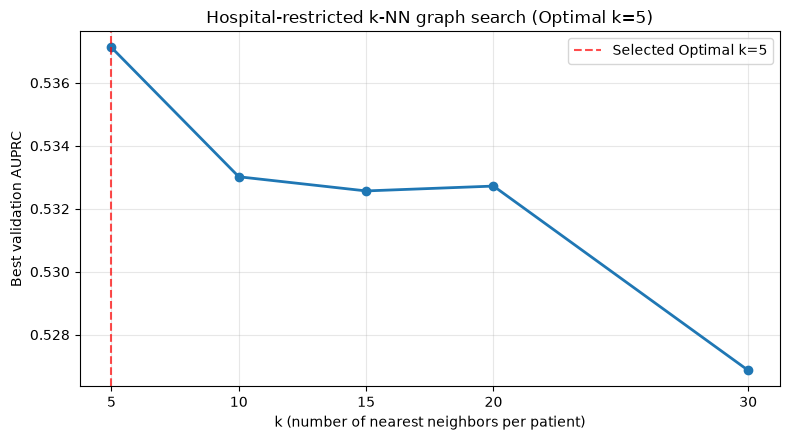

Use K_NEIGHBORS = 5 in the main GCN notebook.
Saved visualization to: /Users/aryandwivedi/Desktop/Project Hail Minor/figures/gcn_k_sensitivity.png


In [15]:
import matplotlib.pyplot as plt

plot_rows = sorted(k_results, key=lambda row: row["k"])
ks = [row["k"] for row in plot_rows]
aps = [row["validation_auprc"] for row in plot_rows]

plt.figure(figsize=(8, 4.5))
plt.plot(ks, aps, marker="o", color="#1f77b4", linewidth=2.0)
plt.axvline(x=BEST_K, color="red", linestyle="--", alpha=0.7, label=f"Selected Optimal k={BEST_K}")
plt.xticks(ks)
plt.xlabel("k (number of nearest neighbors per patient)")
plt.ylabel("Best validation AUPRC")
plt.title(f"Hospital-restricted k-NN graph search (Optimal k={BEST_K})")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

output_path = FIGURES_DIR / "gcn_k_sensitivity.png"
plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"Use K_NEIGHBORS = {BEST_K} in the main GCN notebook.")
print("Saved visualization to:", output_path.resolve())
